# Análisis exploratorio — Cancelaciones hoteleras

**Objetivo:** identificar patrones asociados a `is_canceled` que ayuden al responsable de revenue management a formular hipótesis de seguimiento comercial. Cada sección presenta pregunta, análisis e interpretación, como los proyectos anteriores. Los materiales específicos de ML y requisitos del profesor siguen pendientes: no se les atribuyen decisiones no verificadas.

**Alcance:** EDA completo, sin eliminar registros, imputar valores, entrenar modelos ni decidir predictores definitivos. `df` permanece intacto; `eda` es una copia en memoria con auxiliares de agrupación. No se exporta un dataset procesado.

Este análisis descriptivo usa todo el archivo solicitado. No existe aún una prueba reservada: un futuro holdout de estos datos habrá estado expuesto a exploración. Documentar esta limitación y buscar una validación externa/prospectiva. No se estima rendimiento predictivo ni causalidad.

## 1. Carga, estructura y estadística descriptiva
**Pregunta:** ¿qué datos tenemos y qué significado tienen sus tipos?

### Contexto metodológico

Este análisis describe todo el archivo antes de fijar la prueba definitiva. Las diferencias por hotel, antelación o segmento son asociaciones, no efectos causales. No se eliminan registros ni se ajusta un modelo. La exposición global de los datos se declara como una limitación de la evaluación posterior.

**Qué se hace y por qué.** Preparar rutas y bibliotecas y leer el CSV conservando una huella del original.



In [1]:
# Preparar rutas y bibliotecas y leer el CSV conservando una huella del original.
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/raw/hotel_bookings.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data/raw/hotel_bookings.csv"
REPORT_PATH = PROJECT_ROOT / "reports"
FIGURE_PATH = REPORT_PATH / "figures"
FIGURE_PATH.mkdir(exist_ok=True)
with DATA_PATH.open("rb") as archivo:
    # Calcular una huella determinista para trazabilidad; no usarla como característica predictiva.
    original_sha = hashlib.file_digest(archivo, "sha256").hexdigest()
expected = json.loads((REPORT_PATH / "inspeccion_dataset.json").read_text(encoding="utf-8"))["sha256_csv"]
# La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
assert original_sha == expected
df = pd.read_csv(DATA_PATH, encoding="utf-8", encoding_errors="strict")
original_hash = pd.util.hash_pandas_object(df, index=True).copy()
assert df.is_canceled.isin([0, 1]).all()
print(f"Dimensiones: {len(df):,} filas; {len(df.columns)} columnas")
print(f"Python {platform.python_version()}; pandas {pd.__version__}; NumPy {np.__version__}; seaborn {sns.__version__}")
display(df.head())
semantic_categories = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel", "is_repeated_guest", "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company", "customer_type", "reservation_status"]
schema = pd.DataFrame({"tipo_leido": df.dtypes.astype(str), "n_unicos": df.nunique(), "nulos": df.isna().sum()})
schema["papel"] = ["objetivo" if c == "is_canceled" else "fecha como cadena" if c == "reservation_status_date" else "categórica / identificador" if c in semantic_categories else "numérica / calendario" for c in schema.index]
display(schema)
display(df.describe(percentiles=[.01, .25, .5, .75, .99]).T)
display(df.select_dtypes(exclude="number").describe().T)

Dimensiones: 119,390 filas; 32 columnas
Python 3.14.5; pandas 3.0.3; NumPy 2.4.6; seaborn 0.13.2


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


,tipo_leido,n_unicos,nulos,papel
hotel,str,2,0,categórica / identificador
is_canceled,int64,2,0,objetivo
lead_time,int64,479,0,numérica / calendario
arrival_date_year,int64,3,0,numérica / calendario
arrival_date_month,str,12,0,categórica / identificador
arrival_date_week_number,int64,53,0,numérica / calendario
arrival_date_day_of_month,int64,31,0,numérica / calendario
stays_in_weekend_nights,int64,17,0,numérica / calendario
stays_in_week_nights,int64,35,0,numérica / calendario
adults,int64,14,0,numérica / calendario


,count,mean,std,min,1%,25%,50%,75%,99%,max
is_canceled,"119,390.000",0.370,0.483,0.000,0.000,0.000,0.000,1.000,1.000,1.000
lead_time,"119,390.000",104.011,106.863,0.000,0.000,18.000,69.000,160.000,444.000,737.000
arrival_date_year,"119,390.000","2,016.157",0.707,"2,015.000","2,015.000","2,016.000","2,016.000","2,017.000","2,017.000","2,017.000"
arrival_date_week_number,"119,390.000",27.165,13.605,1.000,2.000,16.000,28.000,38.000,53.000,53.000
arrival_date_day_of_month,"119,390.000",15.798,8.781,1.000,1.000,8.000,16.000,23.000,31.000,31.000
stays_in_weekend_nights,"119,390.000",0.928,0.999,0.000,0.000,0.000,1.000,2.000,4.000,19.000
stays_in_week_nights,"119,390.000",2.500,1.908,0.000,0.000,1.000,2.000,3.000,10.000,50.000
adults,"119,390.000",1.856,0.579,0.000,1.000,2.000,2.000,2.000,3.000,55.000
children,"119,386.000",0.104,0.399,0.000,0.000,0.000,0.000,0.000,2.000,10.000
babies,"119,390.000",0.008,0.097,0.000,0.000,0.000,0.000,0.000,0.000,10.000


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**Interpretación.** `agent` y `company` son identificadores aunque pandas los lea como flotantes. `is_repeated_guest` es binaria; los componentes de llegada son calendario. La etiqueta no será predictor. `reservation_status_date` se lee como cadena. Las medias y máximos deben contrastarse con percentiles y tamaños de grupo; no se corrigen tipos aquí.

**Qué se hace y por qué.** Crear auxiliares descriptivos de fechas, huéspedes y agrupación sin alterar el CSV.



In [2]:
# Crear auxiliares descriptivos de fechas, huéspedes y agrupación sin alterar el CSV.
# Auxiliares solo para describir; se conserva el DataFrame original.
month_names = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
month_map = {name: i + 1 for i, name in enumerate(month_names)}
arrival = pd.to_datetime(pd.DataFrame({"year": df.arrival_date_year, "month": df.arrival_date_month.map(month_map), "day": df.arrival_date_day_of_month}), errors="coerce")
eda = df.assign(arrival_date=arrival, month_number=df.arrival_date_month.map(month_map),
    stay_nights=df.stays_in_week_nights + df.stays_in_weekend_nights,
    guests=df[["adults", "children", "babies"]].sum(axis=1, min_count=3))


def group_summary(column, data=eda):
    """Cuenta reservas y cancelaciones; usa cada grupo como denominador de la tasa."""
    # Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
    table = data.groupby(column, dropna=False, observed=True).is_canceled.agg(reservas="size", cancelaciones="sum", tasa="mean")
    table["porcentaje_reservas"] = 100 * table.reservas / len(data)
    table["tasa_pct"] = 100 * table.tasa
    return table


def show_figure(fig, name):
    """Conserva el gráfico dentro del notebook y como PNG revisable."""
    fig.savefig(FIGURE_PATH / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Auxiliar de eda.
def plot_groups(table, title, name):
    labels = ["Ausente" if pd.isna(x) else str(x) for x in table.index]
    fig, axes = plt.subplots(1, 2, figsize=(13, max(3.6, len(table) * .42)), layout="constrained")
    axes[0].barh(labels, table.reservas, color="#4477AA", label="Reservas")
    axes[0].barh(labels, table.cancelaciones, color="#CC6677", label="Canceladas")
    axes[0].set(xlabel="Número de registros", title=title + ": volumen")
    axes[0].legend()
    axes[1].barh(labels, table.tasa_pct, color="#228833")
    axes[1].set(xlim=(0, 100), xlabel="Tasa de cancelación (%)", title=title + ": tasa")
    for i, value in enumerate(table.tasa_pct):
        axes[1].text(min(value + 1, 88), i, f"{value:.1f}%", va="center", fontsize=9)
    show_figure(fig, name)

results = {"filas": len(df), "columnas": len(df.columns), "sha256_csv": original_sha}

## 2. Calidad: ausencias y distribución
**Pregunta:** ¿cuánta información falta y se concentra por hotel o resultado?

**Qué se hace y por qué.** Cuantificar ausencias globales y por hotel para estudiar su distribución.



,nulos,porcentaje
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003
arrival_date_month,0,0.000
arrival_date_week_number,0,0.000
hotel,0,0.000
is_canceled,0,0.000
stays_in_weekend_nights,0,0.000
arrival_date_day_of_month,0,0.000


,company,agent,country,children
hotel,,,,
City Hotel,95.350,10.250,0.030,0.005
Resort Hotel,92.242,20.492,1.158,0.000


,company,agent,country,children
is_canceled,,,,
0,92.542,16.377,0.560,0.000
1,97.307,9.113,0.152,0.009


,variable,ausente,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
0,company,False,6797,1191,0.175,5.693,17.522
1,company,True,112593,43033,0.382,94.307,38.220
2,agent,False,103050,40194,0.390,86.314,39.004
3,agent,True,16340,4030,0.247,13.686,24.663
4,country,False,118902,44157,0.371,99.591,37.137
5,country,True,488,67,0.137,0.409,13.730
6,children,False,119386,44220,0.370,99.997,37.040
7,children,True,4,4,1.000,0.003,100.000


,company,agent,country,children,reservas,porcentaje
0,True,False,False,False,102677,86.001
1,True,True,False,False,9598,8.039
2,False,True,False,False,6406,5.366
3,False,False,False,False,217,0.182
4,False,True,True,False,174,0.146
5,True,True,True,False,160,0.134
6,True,False,True,False,154,0.129
7,True,True,False,True,2,0.002
8,True,False,False,True,2,0.002


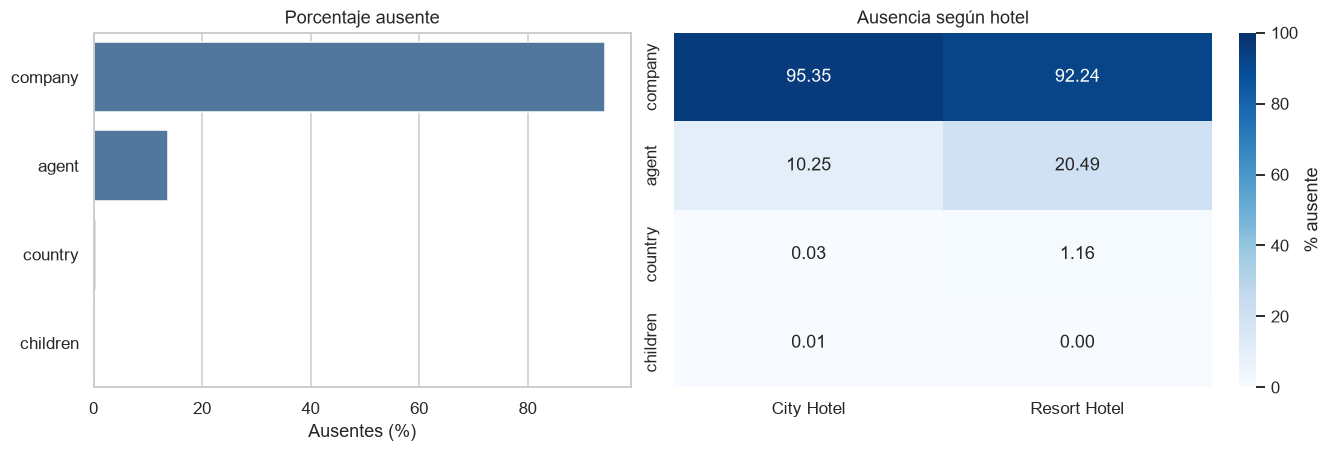

**Interpretación.** `company` falta en 94.31% y `agent` en 13.69%. `country` tiene 488 ausentes y `children`, 4. La ausencia de `agent` alcanza 10.25% en City y 20.49% en Resort; en `country`, 0.03% frente a 1.16%. La ausencia no se distribuye igual por hotel; esto no prueba su mecanismo ni permite asumir ausencia aleatoria. Podría significar que no intervino empresa o agente, pero falta documentación. En fase 3 se distinguirá ausencia estructural de dato desconocido; se valorarán categoría de ausencia, indicadores o imputación, sin convertir desconocido en cero automáticamente. Los parámetros aprendidos se ajustarán solo en entrenamiento.

In [3]:
# Cuantificar ausencias globales y por hotel para estudiar su distribución.
missing = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": 100 * df.isna().mean()}).sort_values("nulos", ascending=False)
display(missing)
missing_columns = missing.index[missing.nulos > 0].tolist()
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
by_hotel = df[missing_columns].isna().groupby(df.hotel).mean().mul(100)
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
by_target = df[missing_columns].isna().groupby(df.is_canceled).mean().mul(100)
display(by_hotel)
display(by_target)
missing_rates = []
for column in missing_columns:
    table = group_summary(df[column].isna().rename("ausente")).reset_index()
    table.insert(0, "variable", column)
    missing_rates.append(table)
display(pd.concat(missing_rates, ignore_index=True))
patterns = df[missing_columns].isna().value_counts().rename("reservas").reset_index()
patterns["porcentaje"] = 100 * patterns.reservas / len(df)
display(patterns)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.barplot(data=missing.loc[missing_columns].reset_index(names="variable"), x="porcentaje", y="variable", color="#4477AA", ax=axes[0])
axes[0].set(title="Porcentaje ausente", xlabel="Ausentes (%)", ylabel="")
sns.heatmap(by_hotel.T, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "% ausente"})
axes[1].set(title="Ausencia según hotel", xlabel="", ylabel="")
show_figure(fig, "01_ausencias")
results["nulos"] = missing.loc[missing_columns].reset_index(names="variable").to_dict("records")
display(Markdown(f"**Interpretación.** `company` falta en {100 * df.company.isna().mean():.2f}% y `agent` en {100 * df.agent.isna().mean():.2f}%. `country` tiene {df.country.isna().sum():,} ausentes y `children`, {df.children.isna().sum()}. La ausencia de `agent` alcanza {by_hotel.loc['City Hotel', 'agent']:.2f}% en City y {by_hotel.loc['Resort Hotel', 'agent']:.2f}% en Resort; en `country`, {by_hotel.loc['City Hotel', 'country']:.2f}% frente a {by_hotel.loc['Resort Hotel', 'country']:.2f}%. La ausencia no se distribuye igual por hotel; esto no prueba su mecanismo ni permite asumir ausencia aleatoria. Podría significar que no intervino empresa o agente, pero falta documentación. En fase 3 se distinguirá ausencia estructural de dato desconocido; se valorarán categoría de ausencia, indicadores o imputación, sin convertir desconocido en cero automáticamente. Los parámetros aprendidos se ajustarán solo en entrenamiento."))

## 3. Calidad: duplicados, extremos e inconsistencias
**Pregunta:** ¿qué observaciones necesitan revisión antes de preparar los datos?

Se cuentan duplicados sobre las 32 columnas originales. La regla de 1,5 × IQR es una señal exploratoria, no una prueba de error. No se elimina ningún registro.

**Qué se hace y por qué.** Distinguir repeticiones adicionales de todas las filas que participan en un grupo repetido.



In [4]:
# Distinguir repeticiones adicionales de todas las filas que participan en un grupo repetido.
duplicate_extra = df.duplicated()
duplicate_group = df.duplicated(keep=False)
print(f"Duplicados adicionales: {duplicate_extra.sum():,} ({100 * duplicate_extra.mean():.2f}%)")
print(f"Registros en grupos repetidos: {duplicate_group.sum():,}")
display(group_summary(duplicate_group.rename("en_grupo_duplicado")))
display(pd.crosstab(df.hotel, duplicate_group, normalize="index").mul(100))
display(df.loc[duplicate_group].head(6))
continuous = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "adults", "children", "babies", "previous_cancellations", "previous_bookings_not_canceled"]
q1, q3 = df[continuous].quantile(.25), df[continuous].quantile(.75)
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
flags = df[continuous].lt(lo) | df[continuous].gt(hi)
display(pd.DataFrame({"p25": q1, "p75": q3, "limite_inferior": lo, "limite_superior": hi, "n_fuera_IQR": flags.sum(), "pct_fuera_no_nulos": 100 * flags.sum() / df[continuous].notna().sum(), "minimo": df[continuous].min(), "maximo": df[continuous].max()}))
checks = {
 "ADR negativo": df.adr < 0, "ADR cero (puede ser válido)": df.adr == 0,
 "Cero noches": eda.stay_nights == 0, "Cero huéspedes conocidos": eda.guests == 0,
 "Huéspedes desconocidos": eda.guests.isna(), "Más de 10 huéspedes (revisar)": eda.guests > 10,
 "Conteos/antelación negativos": df[["lead_time", "adults", "children", "babies", "stays_in_week_nights", "stays_in_weekend_nights", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]].lt(0).any(axis=1),
 "Llegada inválida": eda.arrival_date.isna(),
 "Fecha estado inválida": pd.to_datetime(df.reservation_status_date, errors="coerce").isna(),
 "Repetidor fuera de 0/1": ~df.is_repeated_guest.isin([0, 1])}
anomalies = pd.DataFrame({"registros": {k: int(v.sum()) for k, v in checks.items()}})
anomalies["porcentaje"] = 100 * anomalies.registros / len(df)
display(anomalies)
display(df.select_dtypes(exclude="number").eq("Undefined").sum().to_frame("Undefined"))
display(df.loc[df.adr.lt(0) | df.adr.eq(df.adr.max()), ["hotel", "is_canceled", "adr", "adults", "children", "stays_in_week_nights", "stays_in_weekend_nights"]])
results["duplicados_adicionales"] = int(duplicate_extra.sum())
results["duplicados_grupo"] = int(duplicate_group.sum())
results["anomalias"] = anomalies.reset_index(names="comprobacion").to_dict("records")
display(Markdown(f"**Interpretación.** {duplicate_extra.sum():,} repeticiones adicionales podrían alterar las tasas si se eliminaran. Sin ID único no se distingue duplicación técnica de reservas iguales. ADR va de {df.adr.min():.2f} a {df.adr.max():.2f}; hay {(df.adr < 0).sum()} negativo, {(df.adr == 0).sum():,} ceros, {(eda.stay_nights == 0).sum():,} estancias sin noches y {(eda.guests == 0).sum():,} registros sin huéspedes conocidos. No todos son errores demostrados. Cuando el IQR es cero, cualquier valor positivo puede quedar marcado; no se recorta automáticamente. Las comprobaciones se solapan y no se deben sumar. Fase 3 deberá contrastar semántica y documentar cada tratamiento."))

Duplicados adicionales: 31,994 (26.80%)
Registros en grupos repetidos: 40,165


,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
en_grupo_duplicado,,,,,
False,79225,20773,0.262,66.358,26.220
True,40165,23451,0.584,33.642,58.387


col_0,False,True
hotel,,
City Hotel,59.980,40.020
Resort Hotel,78.989,21.011


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.000,NaN,0,Transient,84.670,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.000,NaN,0,Transient,84.670,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.000,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.000,NaN,0,Transient,137.000,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.000,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.000,NaN,0,Transient,137.000,0,1,Check-Out,2015-07-07


,p25,p75,limite_inferior,limite_superior,n_fuera_IQR,pct_fuera_no_nulos,minimo,maximo
lead_time,18.000,160.000,-195.000,373.000,3005,2.517,0.000,737.000
adr,69.290,126.000,-15.775,211.065,3793,3.177,-6.380,"5,400.000"
stays_in_week_nights,1.000,3.000,-2.000,6.000,3354,2.809,0.000,50.000
stays_in_weekend_nights,0.000,2.000,-3.000,5.000,265,0.222,0.000,19.000
adults,2.000,2.000,2.000,2.000,29710,24.885,0.000,55.000
children,0.000,0.000,0.000,0.000,8590,7.195,0.000,10.000
babies,0.000,0.000,0.000,0.000,917,0.768,0.000,10.000
previous_cancellations,0.000,0.000,0.000,0.000,6484,5.431,0.000,26.000
previous_bookings_not_canceled,0.000,0.000,0.000,0.000,3620,3.032,0.000,72.000


,registros,porcentaje
ADR negativo,1,0.001
ADR cero (puede ser válido),1959,1.641
Cero noches,715,0.599
Cero huéspedes conocidos,180,0.151
Huéspedes desconocidos,4,0.003
Más de 10 huéspedes (revisar),14,0.012
Conteos/antelación negativos,0,0.000
Llegada inválida,0,0.000
Fecha estado inválida,0,0.000
Repetidor fuera de 0/1,0,0.000


,Undefined
hotel,0
arrival_date_month,0
meal,1169
country,0
market_segment,2
distribution_channel,5
reserved_room_type,0
assigned_room_type,0
deposit_type,0
customer_type,0


,hotel,is_canceled,adr,adults,children,stays_in_week_nights,stays_in_weekend_nights
14969,Resort Hotel,0,-6.380,2,0.000,6,4
48515,City Hotel,1,"5,400.000",2,0.000,1,0


**Interpretación.** 31,994 repeticiones adicionales podrían alterar las tasas si se eliminaran. Sin ID único no se distingue duplicación técnica de reservas iguales. ADR va de -6.38 a 5400.00; hay 1 negativo, 1,959 ceros, 715 estancias sin noches y 180 registros sin huéspedes conocidos. No todos son errores demostrados. Cuando el IQR es cero, cualquier valor positivo puede quedar marcado; no se recorta automáticamente. Las comprobaciones se solapan y no se deben sumar. Fase 3 deberá contrastar semántica y documentar cada tratamiento.

## 4. Variable objetivo y hoteles
**Pregunta:** ¿qué proporción cancela y cambia entre hoteles?

**Qué se hace y por qué.** Describir el objetivo y las diferencias entre hoteles mediante conteos y tasas.



,reservas,porcentaje
is_canceled,,
0,75166,62.958
1,44224,37.042


,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
hotel,,,,,
City Hotel,79330,33102,0.417,66.446,41.727
Resort Hotel,40060,11122,0.278,33.554,27.763


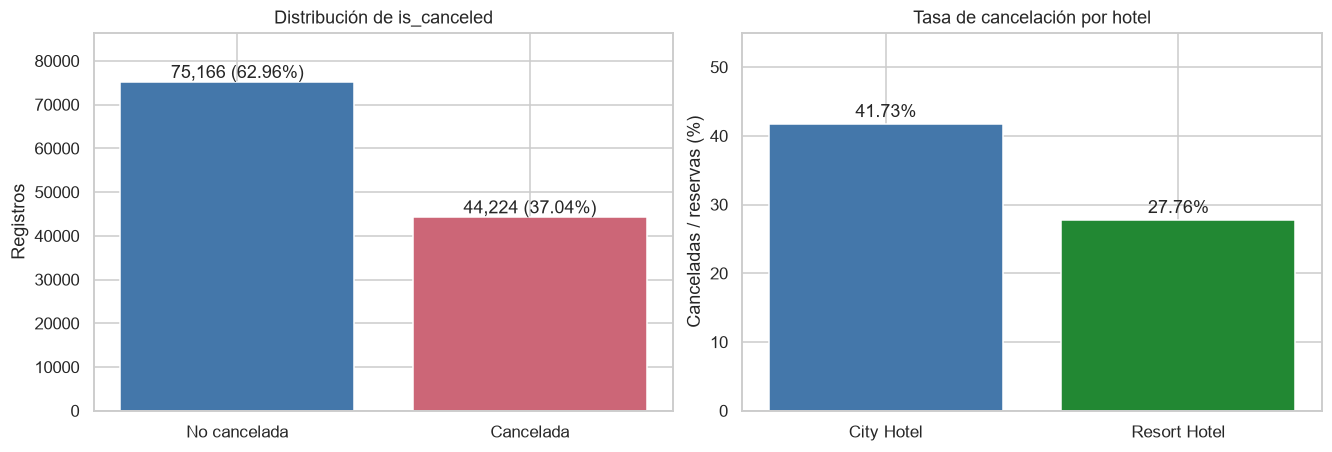

**Interpretación.** Se cancelan 44,224 reservas (37.04%). City Hotel registra 41.73% frente a 27.76% en Resort Hotel, diferencia de 13.96 puntos. City también tiene más registros: cantidad y tasa no son equivalentes. Hay desequilibrio moderado de clases; accuracy por sí sola no bastará para evaluar modelos. Estas tasas no son rendimiento predictivo.

In [5]:
# Describir el objetivo y las diferencias entre hoteles mediante conteos y tasas.
target = df.is_canceled.value_counts().sort_index().rename_axis("is_canceled").to_frame("reservas")
target["porcentaje"] = 100 * target.reservas / len(df)
hotels = group_summary("hotel")
display(target)
display(hotels)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].bar(["No cancelada", "Cancelada"], target.reservas, color=["#4477AA", "#CC6677"])
axes[0].set(title="Distribución de is_canceled", ylabel="Registros", ylim=(0, target.reservas.max() * 1.15))
for i, (n, p) in enumerate(zip(target.reservas, target.porcentaje)):
    axes[0].text(i, n, f"{n:,} ({p:.2f}%)", ha="center", va="bottom")
axes[1].bar(hotels.index, hotels.tasa_pct, color=["#4477AA", "#228833"])
axes[1].set(title="Tasa de cancelación por hotel", ylabel="Canceladas / reservas (%)", ylim=(0, 55))
for i, v in enumerate(hotels.tasa_pct): axes[1].text(i, v + 1, f"{v:.2f}%", ha="center")
show_figure(fig, "02_objetivo_hoteles")
results["objetivo"] = target.reset_index().to_dict("records")
results["hoteles"] = hotels.reset_index().to_dict("records")
display(Markdown(f"**Interpretación.** Se cancelan {int(df.is_canceled.sum()):,} reservas ({100 * df.is_canceled.mean():.2f}%). City Hotel registra {hotels.loc['City Hotel', 'tasa_pct']:.2f}% frente a {hotels.loc['Resort Hotel', 'tasa_pct']:.2f}% en Resort Hotel, diferencia de {hotels.loc['City Hotel', 'tasa_pct'] - hotels.loc['Resort Hotel', 'tasa_pct']:.2f} puntos. City también tiene más registros: cantidad y tasa no son equivalentes. Hay desequilibrio moderado de clases; accuracy por sí sola no bastará para evaluar modelos. Estas tasas no son rendimiento predictivo."))

## 5. Antelación y precio medio diario
**Pregunta:** ¿cómo se distribuyen `lead_time` y `adr`, y cómo se relacionan con la cancelación?

ADR se muestra completo y ampliado hasta P99; se informa cuántos registros quedan fuera de la ampliación. Solo cambia la vista, no los datos almacenados. Las densidades por etiqueta permiten comparar formas con tamaños distintos.

**Qué se hace y por qué.** Representar antelación y tarifa por resultado; los patrones son asociaciones.



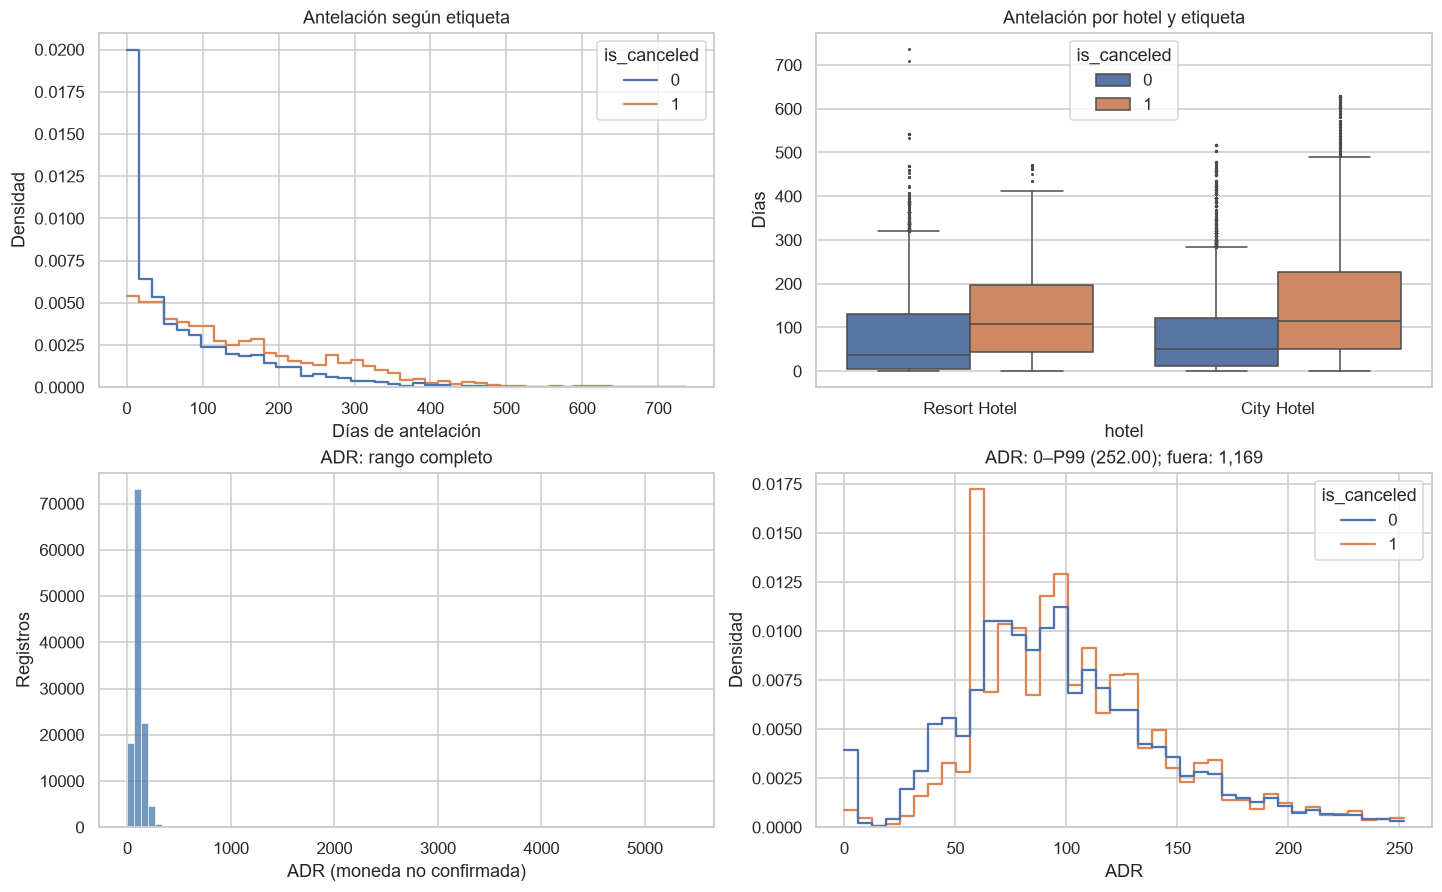

lead_time                             adr                        \
                 size    mean  median min  max   size    mean median    min   
is_canceled                                                                   
0               75166  79.985  45.000   0  737  75166  99.988 92.500 -6.380   
1               44224 144.849 113.000   0  629  44224 104.964 96.200  0.000   

                       
                  max  
is_canceled            
0             510.000  
1           5,400.000

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
antelacion,,,,,
0 días,6345,430,0.068,5.315,6.777
1–7,13401,1472,0.110,11.225,10.984
8–30,18960,5283,0.279,15.881,27.864
31–90,29553,11141,0.377,24.753,37.698
91–180,26439,11821,0.447,22.145,44.710
181–365,21544,11947,0.555,18.045,55.454
>365,3148,2130,0.677,2.637,67.662


,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
rango_adr,,,,,
≤0,1960,213,0.109,1.642,10.867
0–50,10037,2331,0.232,8.407,23.224
50–100,55641,21669,0.389,46.604,38.944
100–150,35244,13724,0.389,29.520,38.940
150–200,11579,4395,0.380,9.698,37.957
200–300,4653,1805,0.388,3.897,38.792
>300,276,87,0.315,0.231,31.522


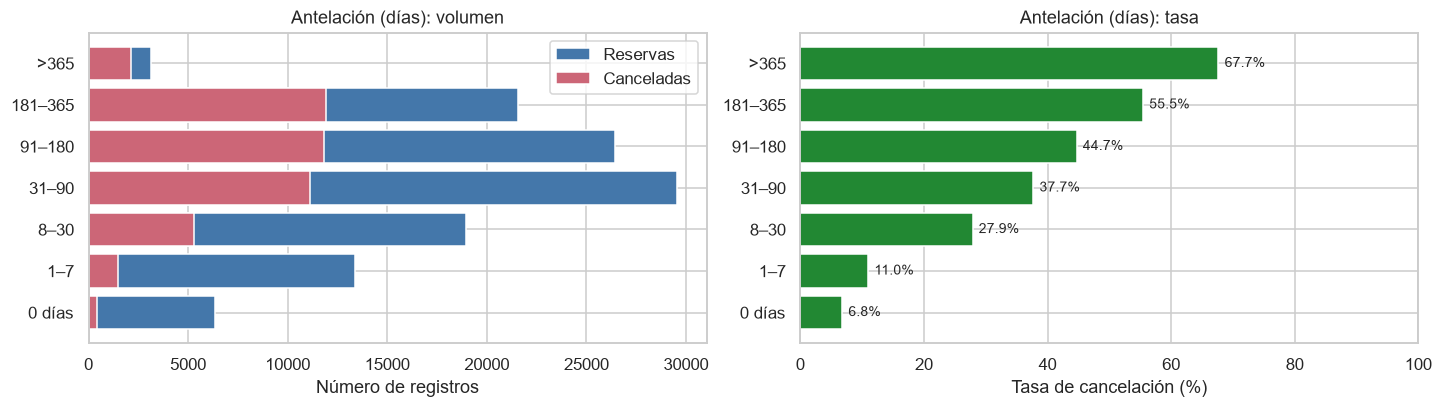

**Interpretación.** La mediana de antelación es 45 días para no canceladas y 113 para canceladas. La tasa pasa de 6.78% el día de llegada a 67.66% por encima de 365 días. Puede reflejar diferencias de segmento, hotel o temporada; no mide un efecto independiente. Las bandas de ADR no deben resumirse como un efecto causal ni necesariamente lineal; el extremo de 5400 distorsiona la escala y requiere revisión. No se excluyen ceros ni negativos de las tablas.

In [6]:
# Representar antelación y tarifa por resultado; los patrones son asociaciones.
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
sns.histplot(data=eda, x="lead_time", hue="is_canceled", bins=45, stat="density", common_norm=False, element="step", fill=False, ax=axes[0, 0])
axes[0, 0].set(title="Antelación según etiqueta", xlabel="Días de antelación", ylabel="Densidad")
sns.boxplot(data=eda, x="hotel", y="lead_time", hue="is_canceled", ax=axes[0, 1], fliersize=1)
axes[0, 1].set(title="Antelación por hotel y etiqueta", ylabel="Días")
sns.histplot(data=eda, x="adr", bins=80, ax=axes[1, 0], color="#4477AA")
axes[1, 0].set(title="ADR: rango completo", xlabel="ADR (moneda no confirmada)", ylabel="Registros")
adr_p99 = df.adr.quantile(.99)
zoom = eda.loc[eda.adr.between(0, adr_p99)]
sns.histplot(data=zoom, x="adr", hue="is_canceled", bins=40, stat="density", common_norm=False, element="step", fill=False, ax=axes[1, 1])
axes[1, 1].set(title=f"ADR: 0–P99 ({adr_p99:.2f}); fuera: {len(eda) - len(zoom):,}", xlabel="ADR", ylabel="Densidad")
show_figure(fig, "03_antelacion_adr")
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
display(eda.groupby("is_canceled")[["lead_time", "adr"]].agg(["size", "mean", "median", "min", "max"]))
lead_band = pd.cut(eda.lead_time, [-np.inf, 0, 7, 30, 90, 180, 365, np.inf], labels=["0 días", "1–7", "8–30", "31–90", "91–180", "181–365", ">365"])
lead_table = group_summary(lead_band.rename("antelacion"))
adr_band = pd.cut(eda.adr, [-np.inf, 0, 50, 100, 150, 200, 300, np.inf], labels=["≤0", "0–50", "50–100", "100–150", "150–200", "200–300", ">300"])
adr_table = group_summary(adr_band.rename("rango_adr"))
display(lead_table)
display(adr_table)
plot_groups(lead_table, "Antelación (días)", "04_tasas_antelacion")
results["antelacion"] = lead_table.reset_index().astype({"antelacion":"str"}).to_dict("records")
results["adr"] = adr_table.reset_index().astype({"rango_adr":"str"}).to_dict("records")
display(Markdown(f"**Interpretación.** La mediana de antelación es {df.loc[df.is_canceled.eq(0), 'lead_time'].median():.0f} días para no canceladas y {df.loc[df.is_canceled.eq(1), 'lead_time'].median():.0f} para canceladas. La tasa pasa de {lead_table.iloc[0].tasa_pct:.2f}% el día de llegada a {lead_table.iloc[-1].tasa_pct:.2f}% por encima de 365 días. Puede reflejar diferencias de segmento, hotel o temporada; no mide un efecto independiente. Las bandas de ADR no deben resumirse como un efecto causal ni necesariamente lineal; el extremo de {df.adr.max():.0f} distorsiona la escala y requiere revisión. No se excluyen ceros ni negativos de las tablas."))

## 6. Depósito, canales, segmento y tipo de cliente
**Pregunta:** ¿qué grupos combinan mayor volumen y mayor tasa de cancelación?

Cada tabla incluye denominadores. Se conservan categorías pequeñas; una tasa de 100% con dos observaciones no demuestra un patrón estable.

**Qué se hace y por qué.** Comparar depósito, canal, segmento y cliente sin convertir la asociación en causalidad.



### Tipo de depósito

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
deposit_type,,,,,
No Deposit,104641,29694,0.284,87.646,28.377
Non Refund,14587,14494,0.994,12.218,99.362
Refundable,162,36,0.222,0.136,22.222


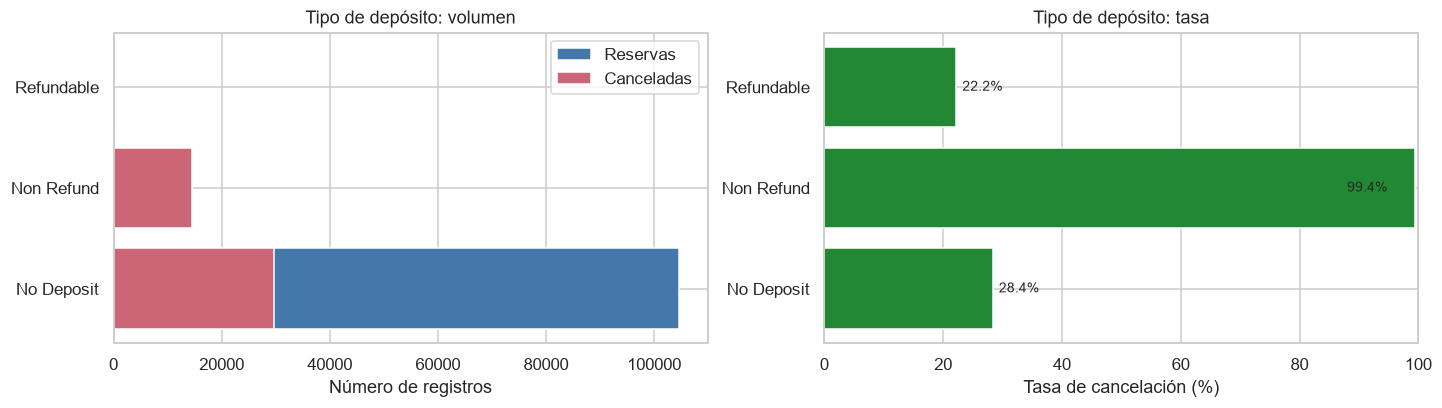

**Interpretación.** Entre categorías con al menos 100 registros (umbral de lectura, no prueba estadística), `Non Refund` tiene la mayor tasa: 99.36% sobre 14,587 reservas. El mayor volumen de cancelaciones corresponde a `No Deposit`. Las categorías pequeñas exigen cautela: volumen y tasa orientan prioridades distintas.

### Canal de distribución

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
distribution_channel,,,,,
TA/TO,97870,40152,0.410,81.975,41.026
Direct,14645,2557,0.175,12.267,17.460
Corporate,6677,1474,0.221,5.593,22.076
GDS,193,37,0.192,0.162,19.171
Undefined,5,4,0.800,0.004,80.000


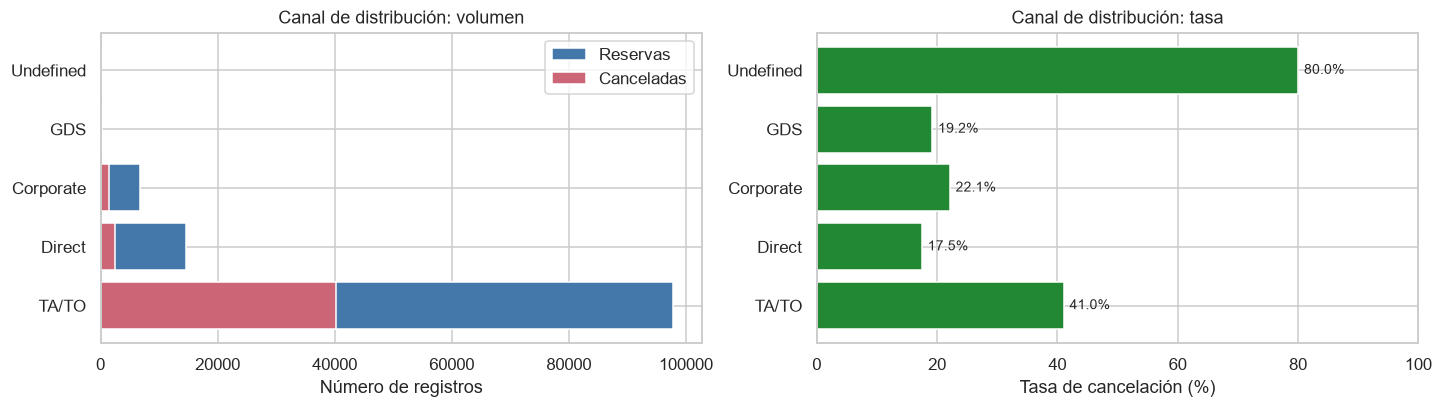

**Interpretación.** Entre categorías con al menos 100 registros (umbral de lectura, no prueba estadística), `TA/TO` tiene la mayor tasa: 41.03% sobre 97,870 reservas. El mayor volumen de cancelaciones corresponde a `TA/TO`. Las categorías pequeñas exigen cautela: volumen y tasa orientan prioridades distintas.

### Segmento de mercado

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
market_segment,,,,,
Online TA,56477,20739,0.367,47.305,36.721
Offline TA/TO,24219,8311,0.343,20.286,34.316
Groups,19811,12097,0.611,16.594,61.062
Direct,12606,1934,0.153,10.559,15.342
Corporate,5295,992,0.187,4.435,18.735
Complementary,743,97,0.131,0.622,13.055
Aviation,237,52,0.219,0.199,21.941
Undefined,2,2,1.000,0.002,100.000


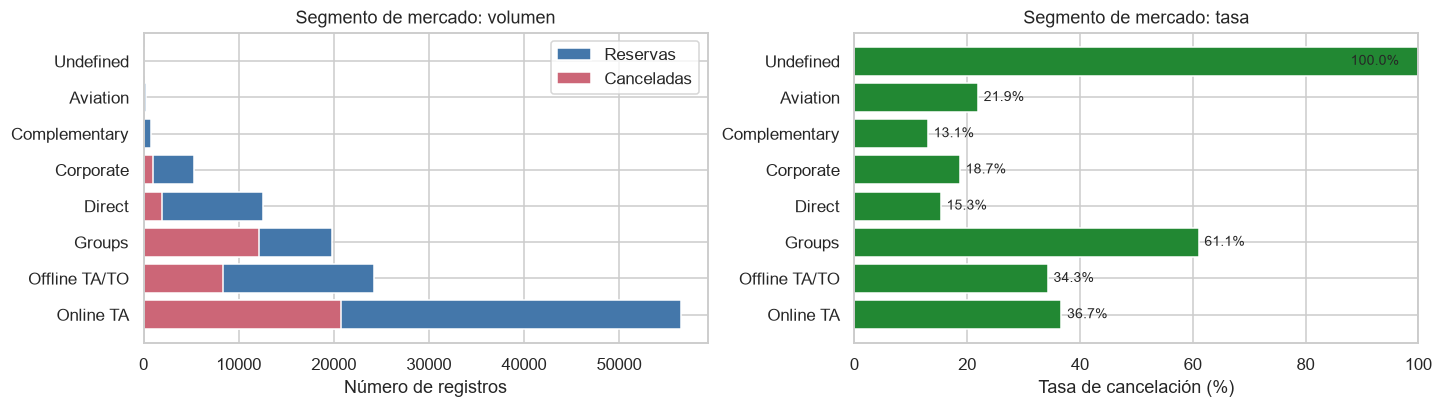

**Interpretación.** Entre categorías con al menos 100 registros (umbral de lectura, no prueba estadística), `Groups` tiene la mayor tasa: 61.06% sobre 19,811 reservas. El mayor volumen de cancelaciones corresponde a `Online TA`. Las categorías pequeñas exigen cautela: volumen y tasa orientan prioridades distintas.

### Tipo de cliente

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
customer_type,,,,,
Transient,89613,36514,0.407,75.059,40.746
Transient-Party,25124,6389,0.254,21.044,25.430
Contract,4076,1262,0.310,3.414,30.962
Group,577,59,0.102,0.483,10.225


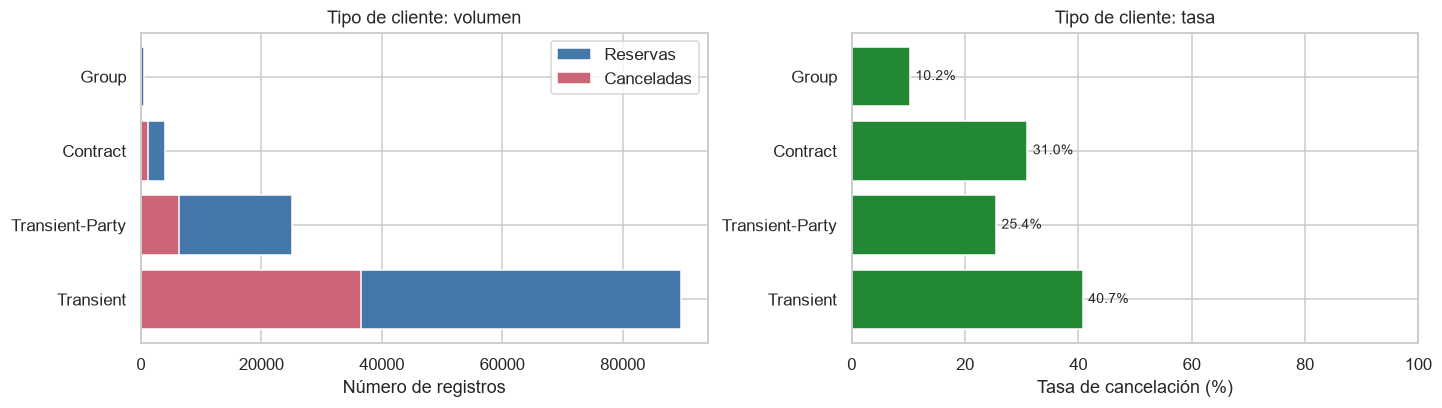

**Interpretación.** Entre categorías con al menos 100 registros (umbral de lectura, no prueba estadística), `Transient` tiene la mayor tasa: 40.75% sobre 89,613 reservas. El mayor volumen de cancelaciones corresponde a `Transient`. Las categorías pequeñas exigen cautela: volumen y tasa orientan prioridades distintas.

reservas  cancelaciones  tasa  tasa_pct
hotel        deposit_type                                         
City Hotel   No Deposit       66442          20244 0.305    30.469
             Non Refund       12868          12844 0.998    99.813
             Refundable          20             14 0.700    70.000
Resort Hotel No Deposit       38199           9450 0.247    24.739
             Non Refund        1719           1650 0.960    95.986
             Refundable         142             22 0.155    15.493

**Depósito.** `Non Refund` tiene 14,587 reservas y 99.36% de cancelación. Esta asociación extraordinaria exige revisar definición, selección comercial y momento de registro. No demuestra por sí sola leakage ni que un depósito cause cancelaciones. Se contrasta por hotel; no se asume independencia de las demás características.

In [7]:
# Comparar depósito, canal, segmento y cliente sin convertir la asociación en causalidad.
commercial_tables = {}
for column, label in [("deposit_type", "Tipo de depósito"), ("distribution_channel", "Canal de distribución"), ("market_segment", "Segmento de mercado"), ("customer_type", "Tipo de cliente")]:
    table = group_summary(column).sort_values("reservas", ascending=False)
    commercial_tables[column] = table
    display(Markdown(f"### {label}"))
    display(table)
    plot_groups(table, label, f"05_{column}")
    supported = table.loc[table.reservas >= 100]
    high = supported.tasa_pct.idxmax()
    display(Markdown(f"**Interpretación.** Entre categorías con al menos 100 registros (umbral de lectura, no prueba estadística), `{high}` tiene la mayor tasa: {supported.loc[high, 'tasa_pct']:.2f}% sobre {int(supported.loc[high, 'reservas']):,} reservas. El mayor volumen de cancelaciones corresponde a `{table.cancelaciones.idxmax()}`. Las categorías pequeñas exigen cautela: volumen y tasa orientan prioridades distintas."))
    results[column] = table.reset_index().to_dict("records")
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
deposit_hotel = eda.groupby(["hotel", "deposit_type"], observed=True).is_canceled.agg(reservas="size", cancelaciones="sum", tasa="mean")
deposit_hotel["tasa_pct"] = 100 * deposit_hotel.tasa
display(deposit_hotel)
display(Markdown(f"**Depósito.** `Non Refund` tiene {int(commercial_tables['deposit_type'].loc['Non Refund', 'reservas']):,} reservas y {commercial_tables['deposit_type'].loc['Non Refund', 'tasa_pct']:.2f}% de cancelación. Esta asociación extraordinaria exige revisar definición, selección comercial y momento de registro. No demuestra por sí sola leakage ni que un depósito cause cancelaciones. Se contrasta por hotel; no se asume independencia de las demás características."))

## 7. Historial y solicitudes especiales
**Pregunta:** ¿las reservas repetidas, antecedentes y solicitudes se asocian con la cancelación?

Los contadores históricos se agrupan en cero/positivo para evitar numerosas categorías pequeñas. Debe verificarse que se calcularon únicamente con hechos conocidos antes de crear la reserva.

**Qué se hace y por qué.** Examinar historial y solicitudes; su disponibilidad histórica todavía debe auditarse.



### is_repeated_guest

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
is_repeated_guest,,,,,
0,115580,43672,0.378,96.809,37.785
1,3810,552,0.145,3.191,14.488


### previous_cancellations

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
previous_cancellations_positivo,,,,,
False,112906,38282,0.339,94.569,33.906
True,6484,5942,0.916,5.431,91.641


### previous_bookings_not_canceled

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
previous_bookings_not_canceled_positivo,,,,,
False,115770,44024,0.380,96.968,38.027
True,3620,200,0.055,3.032,5.525


### total_of_special_requests

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
total_of_special_requests,,,,,
0,70318,33556,0.477,58.898,47.720
1,33226,7318,0.220,27.830,22.025
2,12969,2866,0.221,10.863,22.099
3,2497,446,0.179,2.091,17.861
4,340,36,0.106,0.285,10.588
5,40,2,0.050,0.034,5.000


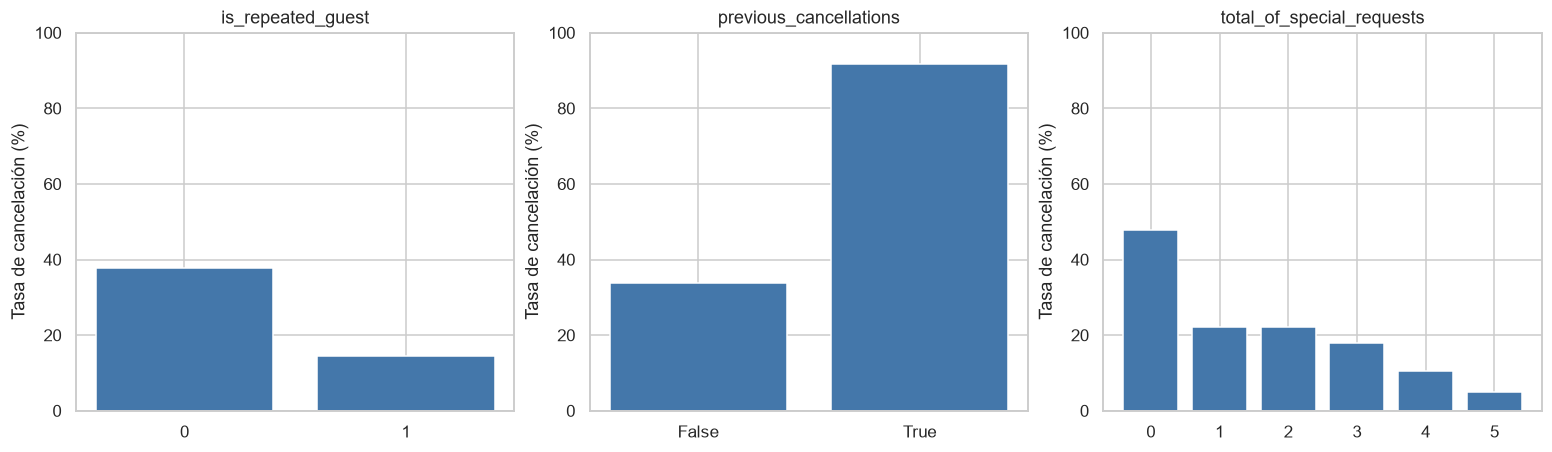

**Interpretación.** Repetidores: 14.49% frente a 37.79% en el resto, sobre solo 3,810 reservas repetidas. Sin solicitudes la tasa es 47.72%, y con una, 22.02%. Las tablas separan antecedentes de cancelación y de reservas no canceladas. Estas asociaciones no acreditan causalidad; el historial debe ser estrictamente anterior y las solicitudes deben reflejar su valor inicial. Cero antecedentes tampoco significa que el huésped nunca haya reservado fuera de estos hoteles.

**Antecedentes.** Con cancelaciones previas la tasa es 91.64% (6,484 reservas) frente a 33.91% sin ellas. Con reservas previas no canceladas, 5.52% frente a 38.03%. La asociación exige comprobar cómo y cuándo se construyeron los contadores.

,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
solicita_aparcamiento,,,,,
False,111974,44224,0.395,93.788,39.495
True,7416,0,0.000,6.212,0.000


**Otra variable relevante.** Con aparcamiento solicitado hay 7,416 registros y 0.00% de cancelación. Esta separación extrema exige verificar que la petición se conocía al reservar y no se actualizó después; no se presenta como regla de riesgo fiable ni como evidencia suficiente de leakage.

In [8]:
# Examinar historial y solicitudes; su disponibilidad histórica todavía debe auditarse.
history_tables = {}
for column in ["is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled", "total_of_special_requests"]:
    grouping = column if column in ["is_repeated_guest", "total_of_special_requests"] else eda[column].gt(0).rename(column + "_positivo")
    table = group_summary(grouping)
    history_tables[column] = table
    display(Markdown(f"### {column}"))
    display(table)
    results[column] = table.reset_index().to_dict("records")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, column in zip(axes, ["is_repeated_guest", "previous_cancellations", "total_of_special_requests"]):
    table = history_tables[column]
    ax.bar([str(x) for x in table.index], table.tasa_pct, color="#4477AA")
    ax.set(title=column, ylabel="Tasa de cancelación (%)", ylim=(0, 100))
show_figure(fig, "06_historial_solicitudes")
repeat = history_tables["is_repeated_guest"]
requests = history_tables["total_of_special_requests"]
display(Markdown(f"**Interpretación.** Repetidores: {repeat.loc[1, 'tasa_pct']:.2f}% frente a {repeat.loc[0, 'tasa_pct']:.2f}% en el resto, sobre solo {int(repeat.loc[1, 'reservas']):,} reservas repetidas. Sin solicitudes la tasa es {requests.loc[0, 'tasa_pct']:.2f}%, y con una, {requests.loc[1, 'tasa_pct']:.2f}%. Las tablas separan antecedentes de cancelación y de reservas no canceladas. Estas asociaciones no acreditan causalidad; el historial debe ser estrictamente anterior y las solicitudes deben reflejar su valor inicial. Cero antecedentes tampoco significa que el huésped nunca haya reservado fuera de estos hoteles."))
prior_cancel = history_tables["previous_cancellations"]
prior_ok = history_tables["previous_bookings_not_canceled"]
display(Markdown(f"**Antecedentes.** Con cancelaciones previas la tasa es {prior_cancel.loc[True, 'tasa_pct']:.2f}% ({int(prior_cancel.loc[True, 'reservas']):,} reservas) frente a {prior_cancel.loc[False, 'tasa_pct']:.2f}% sin ellas. Con reservas previas no canceladas, {prior_ok.loc[True, 'tasa_pct']:.2f}% frente a {prior_ok.loc[False, 'tasa_pct']:.2f}%. La asociación exige comprobar cómo y cuándo se construyeron los contadores."))
parking = group_summary(eda.required_car_parking_spaces.gt(0).rename("solicita_aparcamiento"))
display(parking)
results["aparcamiento"] = parking.reset_index().to_dict("records")
display(Markdown(f"**Otra variable relevante.** Con aparcamiento solicitado hay {int(parking.loc[True, 'reservas']):,} registros y {parking.loc[True, 'tasa_pct']:.2f}% de cancelación. Esta separación extrema exige verificar que la petición se conocía al reservar y no se actualizó después; no se presenta como regla de riesgo fiable ni como evidencia suficiente de leakage."))


## 8. Estancia y huéspedes
**Pregunta:** ¿cambia la tasa según duración prevista o composición de huéspedes?

Se suman noches laborables y de fin de semana. El total de huéspedes solo se calcula si se conocen adultos, niños y bebés: `min_count=3` evita tratar los cuatro `children` ausentes como cero.

**Qué se hace y por qué.** Agrupar duración y huéspedes para describir cancelaciones y casos anómalos.



,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
noches,,,,,
0,715,35,0.049,0.599,4.895
1,21020,5271,0.251,17.606,25.076
2–3,54719,23514,0.430,45.832,42.972
4–7,37679,13525,0.359,31.560,35.895
8–14,4818,1636,0.340,4.036,33.956
>14,439,243,0.554,0.368,55.353


,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
huespedes,,,,,
0,180,25,0.139,0.151,13.889
1,22581,6555,0.290,18.914,29.029
2,82048,32569,0.397,68.723,39.695
3,10494,3376,0.322,8.790,32.171
4,3929,1646,0.419,3.291,41.894
>4,154,49,0.318,0.129,31.818
NaN,4,4,1.000,0.003,100.000


stay_nights            guests               adults             \
                   mean median max   mean median    max   mean median max   
is_canceled                                                                 
0                 3.393  3.000  69  1.942  2.000 12.000  1.830  2.000   4   
1                 3.487  3.000  56  2.012  2.000 55.000  1.902  2.000  55   

            children               babies             
                mean median    max   mean median max  
is_canceled                                           
0              0.102  0.000  3.000  0.010  0.000  10  
1              0.107  0.000 10.000  0.004  0.000   2

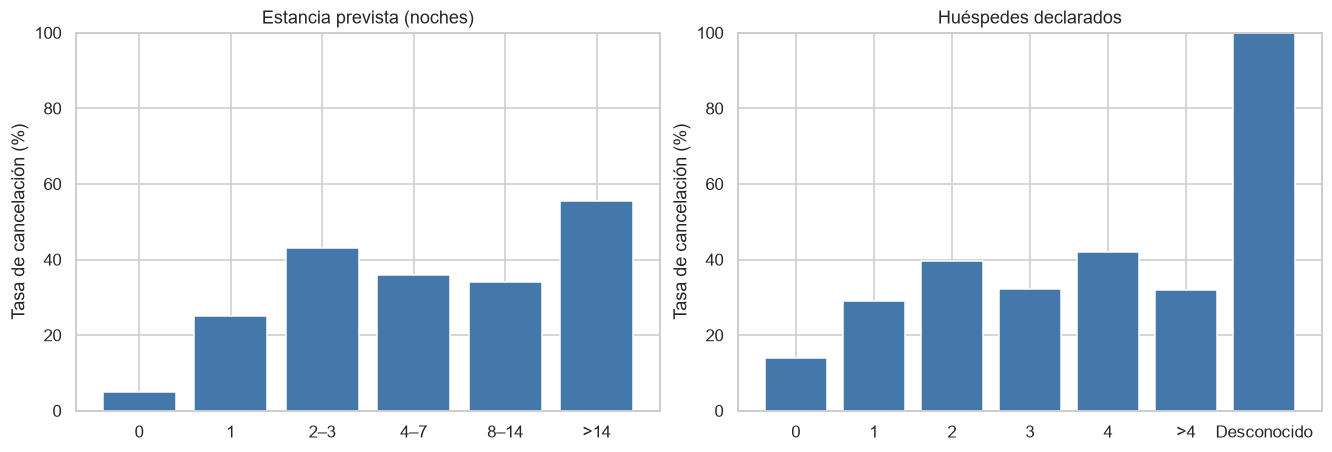

**Interpretación.** La mediana es 3 noches y 2 huéspedes conocidos. Los 4 totales desconocidos se presentan aparte. Las tasas por bandas se acompañan de tamaños de grupo para no sobrerrepresentar estancias largas o reservas grandes. Las estancias de 2–3 noches presentan 42.97%, frente al 35.90% en 4–7; no hay una relación simplemente creciente. No se justifica eliminar grupos por su tasa. Cero noches y cero huéspedes deben revisarse con negocio; estas distribuciones no demuestran efectos causales.

In [9]:
# Agrupar duración y huéspedes para describir cancelaciones y casos anómalos.
stay_band = pd.cut(eda.stay_nights, [-np.inf, 0, 1, 3, 7, 14, np.inf], labels=["0", "1", "2–3", "4–7", "8–14", ">14"])
guest_band = pd.cut(eda.guests, [-np.inf, 0, 1, 2, 3, 4, np.inf], labels=["0", "1", "2", "3", "4", ">4"])
stay_table = group_summary(stay_band.rename("noches"))
guest_table = group_summary(guest_band.rename("huespedes"))
display(stay_table)
display(guest_table)
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
display(eda.groupby("is_canceled")[["stay_nights", "guests", "adults", "children", "babies"]].agg(["mean", "median", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, table, title in [(axes[0], stay_table, "Estancia prevista (noches)"), (axes[1], guest_table, "Huéspedes declarados")]:
    ax.bar(["Desconocido" if pd.isna(x) else str(x) for x in table.index], table.tasa_pct, color="#4477AA")
    ax.set(title=title, ylabel="Tasa de cancelación (%)", ylim=(0, 100))
show_figure(fig, "07_estancia_huespedes")
results["estancia"] = stay_table.reset_index().astype({"noches":"str"}).to_dict("records")
results["huespedes"] = guest_table.reset_index().assign(huespedes=lambda table: table.huespedes.astype("str").fillna("Desconocido")).to_dict("records")
display(Markdown(f"**Interpretación.** La mediana es {eda.stay_nights.median():.0f} noches y {eda.guests.median():.0f} huéspedes conocidos. Los {eda.guests.isna().sum()} totales desconocidos se presentan aparte. Las tasas por bandas se acompañan de tamaños de grupo para no sobrerrepresentar estancias largas o reservas grandes. Las estancias de 2–3 noches presentan {stay_table.loc['2–3', 'tasa_pct']:.2f}%, frente al {stay_table.loc['4–7', 'tasa_pct']:.2f}% en 4–7; no hay una relación simplemente creciente. No se justifica eliminar grupos por su tasa. Cero noches y cero huéspedes deben revisarse con negocio; estas distribuciones no demuestran efectos causales."))

## 9. Evolución temporal y estacionalidad
**Pregunta:** ¿cómo varían volumen y tasas por llegada y hotel?

La fecha reconstruida es **llegada prevista**, no creación ni cancelación. Las cancelaciones se agrupan por la llegada prevista de cada reserva. Los paneles separan reservas, cancelaciones y tasa. Los meses del año agregados mezclan periodos con diferente cobertura.

**Qué se hace y por qué.** Resumir volúmenes y tasas por mes de llegada, diferenciando calendario y fecha de reserva.



,reservas,cancelaciones,tasa_pct
mes_llegada,,,
2015-07,2776,1259,45.353
2015-08,3889,1598,41.090
2015-09,5114,2094,40.946
2015-10,4957,1732,34.940
2015-11,2340,486,20.769
2015-12,2920,973,33.322
2016-01,2248,557,24.778
2016-02,3891,1337,34.361
2016-03,4824,1477,30.618


,reservas,cancelaciones,tasa,porcentaje_reservas,tasa_pct
arrival_date_year,,,,,
2015,21996,8142,0.370,18.424,37.016
2016,56707,20337,0.359,47.497,35.863
2017,40687,15745,0.387,34.079,38.698


,primera,ultima,fechas_observadas
hotel,,,
City Hotel,2015-07-01,2017-08-31,793
Resort Hotel,2015-07-01,2017-08-31,793


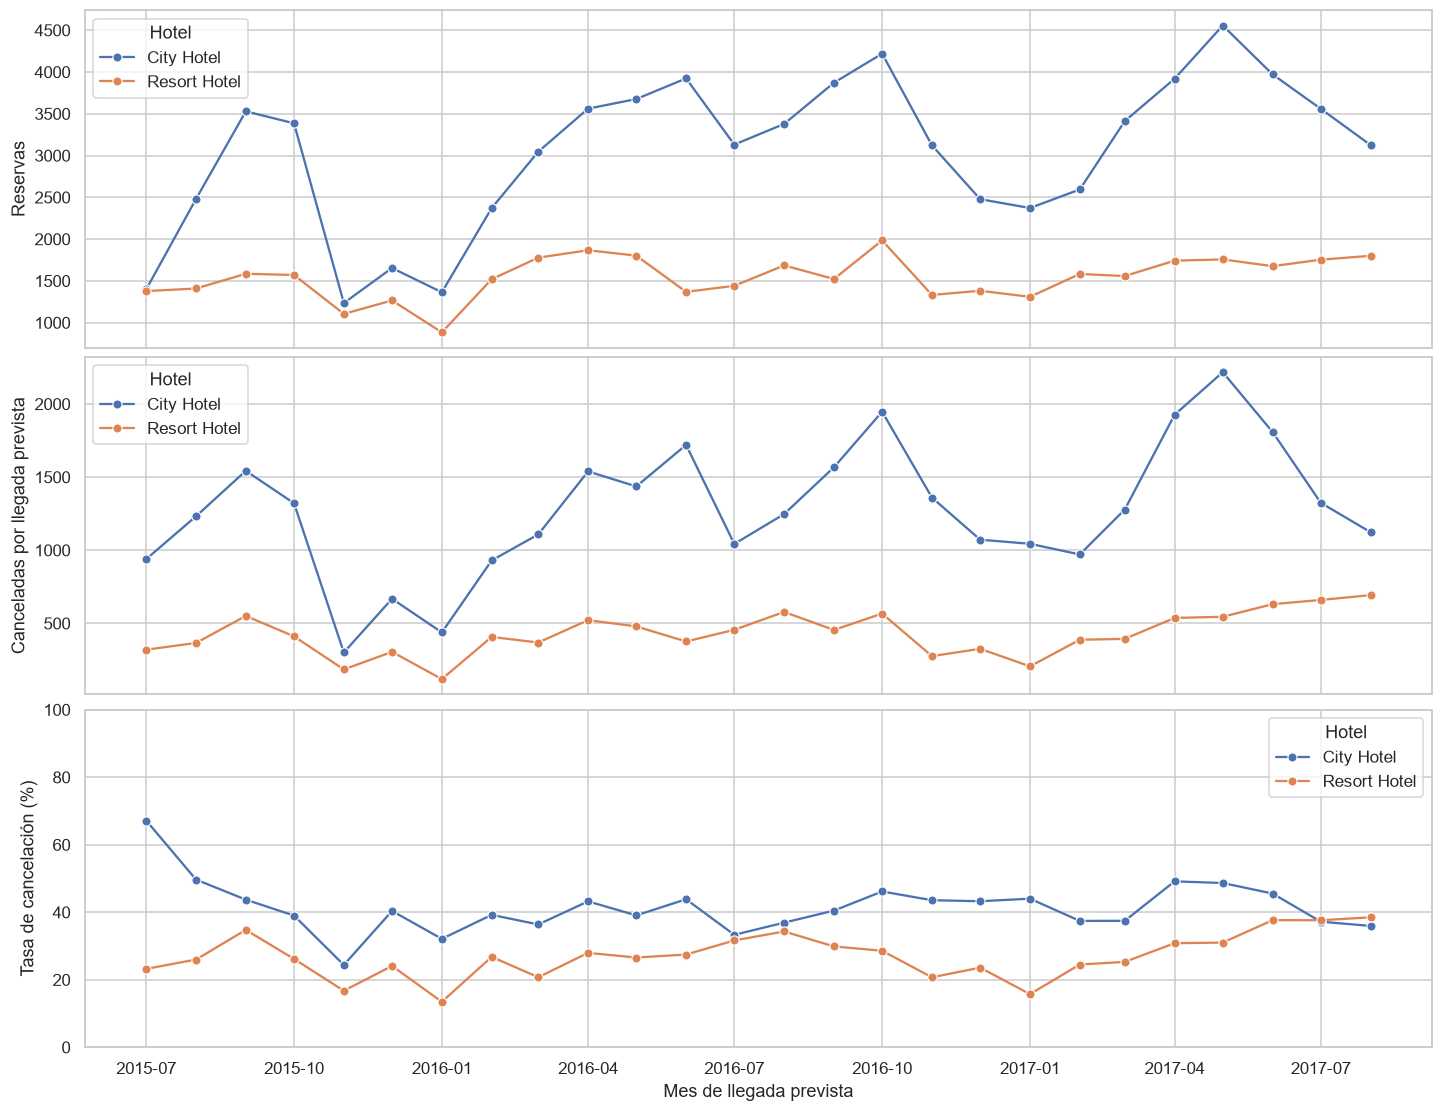

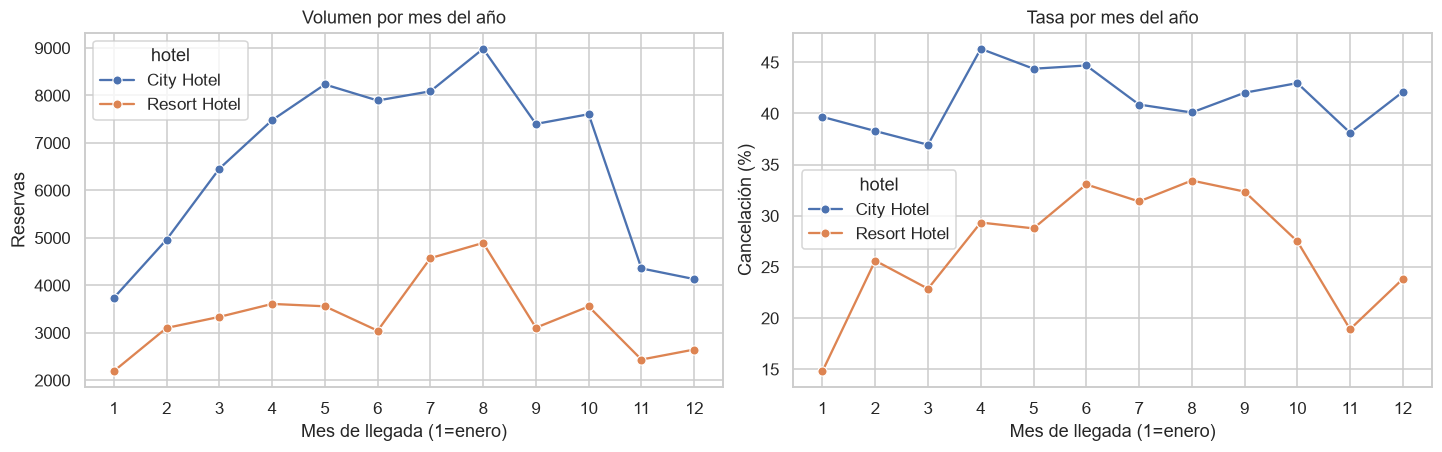

reservas  tasa
arrival_date_year month_number                
2015              7                 2776 0.454
                  8                 3889 0.411
                  9                 5114 0.409
                  10                4957 0.349
                  11                2340 0.208
                  12                2920 0.333
2016              1                 2248 0.248
                  2                 3891 0.344
                  3                 4824 0.306
                  4                 5428 0.380
                  5                 5478 0.350
                  6                 5292 0.396
                  7                 4572 0.328
                  8                 5063 0.360
                  9                 5394 0.375
                  10                6203 0.405
                  11                4454 0.367
                  12                3860 0.362
2017              1                 3681 0.340
                  2                 4177 0.325
                  3                 4970 0.336
                  4                 5661 0.435
                  5                 6313 0.438
                  6                 5647 0.432
                  7                 5313 0.373
                  8                 4925 0.369

**Interpretación.** Cobertura: 01/07/2015 a 31/08/2017. Solo 2016 incluye enero–diciembre: 2015 empieza en julio y 2017 termina en agosto. Los totales anuales y los meses del año no son directamente comparables sin ajustar cobertura. La tasa mensual agregada oscila de 20.77% (2015-11) a 45.35% (2015-07). Hay variación temporal descriptiva por hotel; poco más de dos años no prueba estacionalidad estable ni aísla cambios comerciales. Estas curvas no describen cuándo se recibieron o cancelaron las reservas.

In [10]:
# Resumir volúmenes y tasas por mes de llegada, diferenciando calendario y fecha de reserva.
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
monthly = eda.groupby([eda.arrival_date.dt.to_period("M").rename("mes_llegada"), "hotel"], observed=True).is_canceled.agg(reservas="size", cancelaciones="sum", tasa="mean").reset_index()
monthly["tasa_pct"] = 100 * monthly.tasa
monthly["fecha"] = monthly.mes_llegada.dt.to_timestamp()
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
monthly_total = monthly.groupby("mes_llegada")[["reservas", "cancelaciones"]].sum()
monthly_total["tasa_pct"] = 100 * monthly_total.cancelaciones / monthly_total.reservas
display(monthly_total)
yearly = group_summary("arrival_date_year")
display(yearly)
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
display(eda.groupby("hotel").arrival_date.agg(primera="min", ultima="max", fechas_observadas="nunique"))
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, layout="constrained")
for ax, metric, label in zip(axes, ["reservas", "cancelaciones", "tasa_pct"], ["Reservas", "Canceladas por llegada prevista", "Tasa de cancelación (%)"]):
    sns.lineplot(data=monthly, x="fecha", y=metric, hue="hotel", marker="o", ax=ax)
    ax.set(ylabel=label, xlabel="Mes de llegada prevista")
    if metric == "tasa_pct": ax.set_ylim(0, 100)
    ax.legend(title="Hotel")
show_figure(fig, "08_evolucion_temporal")
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
seasonal = eda.groupby(["month_number", "hotel"], observed=True).is_canceled.agg(reservas="size", cancelaciones="sum", tasa="mean").reset_index()
seasonal["tasa_pct"] = 100 * seasonal.tasa
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for ax, metric, title in [(axes[0], "reservas", "Volumen por mes del año"), (axes[1], "tasa_pct", "Tasa por mes del año")]:
    sns.lineplot(data=seasonal, x="month_number", y=metric, hue="hotel", marker="o", ax=ax)
    ax.set(title=title, xlabel="Mes de llegada (1=enero)", xticks=range(1, 13), ylabel="Reservas" if metric == "reservas" else "Cancelación (%)")
show_figure(fig, "09_estacionalidad")
# Resumir la misma población por grupos y conservar sus denominadores antes de comparar tasas.
display(eda.groupby(["arrival_date_year", "month_number"], observed=True).is_canceled.agg(reservas="size", tasa="mean"))
results["cobertura"] = {"inicio": str(eda.arrival_date.min().date()), "fin": str(eda.arrival_date.max().date())}
results["anual"] = yearly.reset_index().to_dict("records")
results["mensual"] = monthly_total.reset_index().astype({"mes_llegada":"str"}).to_dict("records")
low_month, high_month = monthly_total.tasa_pct.idxmin(), monthly_total.tasa_pct.idxmax()
display(Markdown(f"**Interpretación.** Cobertura: {eda.arrival_date.min():%d/%m/%Y} a {eda.arrival_date.max():%d/%m/%Y}. Solo 2016 incluye enero–diciembre: 2015 empieza en julio y 2017 termina en agosto. Los totales anuales y los meses del año no son directamente comparables sin ajustar cobertura. La tasa mensual agregada oscila de {monthly_total.loc[low_month, 'tasa_pct']:.2f}% ({low_month}) a {monthly_total.loc[high_month, 'tasa_pct']:.2f}% ({high_month}). Hay variación temporal descriptiva por hotel; poco más de dos años no prueba estacionalidad estable ni aísla cambios comerciales. Estas curvas no describen cuándo se recibieron o cancelaron las reservas."))

## 10. Correlaciones numéricas
**Pregunta:** ¿qué asociaciones lineales o monótonas aparecen entre magnitudes?

Se excluyen `agent` y `company` por ser identificadores, y los componentes de calendario por no representar una magnitud lineal útil (mes y día son cíclicos). La etiqueta se incluye solo como referencia descriptiva. Algunas variables tienen riesgo temporal, revisado después. La correlación por pares usa tamaños ligeramente distintos por los cuatro `children` ausentes, sin imputación.

**Qué se hace y por qué.** Examinar correlaciones como descripción, sin seleccionar predictores automáticamente.



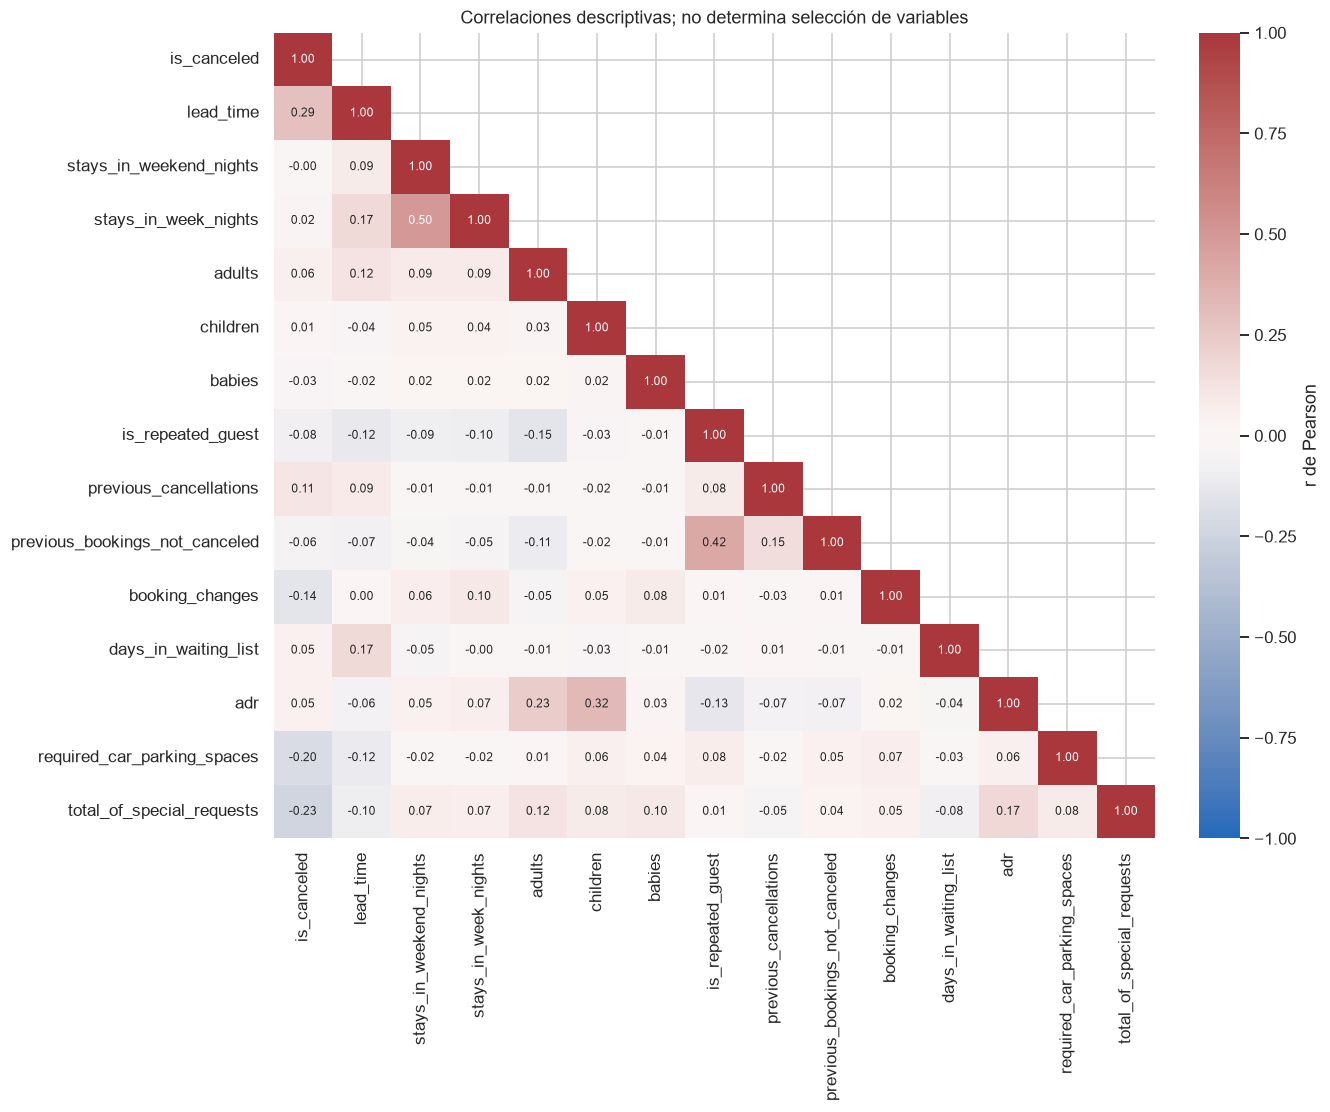

,Pearson,Spearman,abs_Pearson
lead_time,0.293,0.317,0.293
total_of_special_requests,-0.235,-0.259,0.235
required_car_parking_spaces,-0.195,-0.197,0.195
booking_changes,-0.144,-0.185,0.144
previous_cancellations,0.110,0.270,0.110
is_repeated_guest,-0.085,-0.085,0.085
adults,0.060,0.067,0.060
previous_bookings_not_canceled,-0.057,-0.115,0.057
days_in_waiting_list,0.054,0.098,0.054
adr,0.048,0.051,0.048


**Interpretación.** La mayor correlación absoluta de Pearson con la etiqueta de esta selección corresponde a `lead_time` (r=0.293). Las diferencias con Spearman pueden reflejar extremos, asimetrías o relaciones no lineales. Correlación baja no descarta utilidad predictiva; correlación alta no acredita disponibilidad temporal. Las bandas y comparaciones por hotel complementan estas cifras. No se eliminan variables por esta matriz ni se deduce causalidad o rendimiento de clasificación.

In [11]:
# Examinar correlaciones como descripción, sin seleccionar predictores automáticamente.
corr_columns = ["is_canceled", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]
corr = eda[corr_columns].corr(method="pearson")
spearman = eda[corr_columns].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax, cbar_kws={"label": "r de Pearson"})
ax.set_title("Correlaciones descriptivas; no determina selección de variables")
show_figure(fig, "10_correlaciones")
target_corr = pd.DataFrame({"Pearson": corr.is_canceled, "Spearman": spearman.is_canceled}).drop(index="is_canceled")
target_corr["abs_Pearson"] = target_corr.Pearson.abs()
target_corr = target_corr.sort_values("abs_Pearson", ascending=False)
display(target_corr)
results["correlacion_objetivo"] = target_corr.reset_index(names="variable").to_dict("records")
display(Markdown(f"**Interpretación.** La mayor correlación absoluta de Pearson con la etiqueta de esta selección corresponde a `{target_corr.index[0]}` (r={target_corr.iloc[0].Pearson:.3f}). Las diferencias con Spearman pueden reflejar extremos, asimetrías o relaciones no lineales. Correlación baja no descarta utilidad predictiva; correlación alta no acredita disponibilidad temporal. Las bandas y comparaciones por hotel complementan estas cifras. No se eliminan variables por esta matriz ni se deduce causalidad o rendimiento de clasificación."))

## 11. Auditoría de data leakage
**Pregunta:** ¿qué se conoce al crear la reserva y qué recoge el desenlace o cambios posteriores?

Se predice **al crear la reserva**. Una asociación fuerte no demuestra fuga: importa cuándo se registró el valor. “Potencialmente utilizable” queda condicionado a que se conserve el valor inicial. Esta auditoría no implementa todavía exclusiones ni transformaciones.

**Qué se hace y por qué.** Documentar qué campos revelan resultados y cuáles tienen disponibilidad incierta.



In [12]:
# Documentar qué campos revelan resultados y cuáles tienen disponibilidad incierta.
leakage_rows = [
 ("is_canceled", "Objetivo; nunca predictor", "Etiqueta que se quiere predecir."),
 ("reservation_status", "No utilizable", "Estado final: revela cancelación, check-out o no-show."),
 ("reservation_status_date", "No utilizable", "Fecha del último estado; incorpora desenlace/actualizaciones."),
 ("assigned_room_type", "Verificar disponibilidad", "Puede asignarse inicialmente o cambiar cerca de llegada; solo sería válido un valor inicial acreditado."),
 ("booking_changes", "Verificar; alto riesgo", "El total final de cambios aún no existe al crear la reserva; distinguir valor inicial de acumulado final."),
 ("days_in_waiting_list", "Verificar instante de predicción", "Al entrar en espera no se conoce la espera futura; al confirmar podría conocerse la espera transcurrida."),
 ("deposit_type", "Verificar disponibilidad", "La política podría fijarse al reservar; acreditar que no sea un estado/política posterior. Asociación extrema no prueba fuga."),
 ("adr", "Verificar disponibilidad", "Precio inicial puede conocerse; un promedio final puede reflejar modificaciones."),
 ("required_car_parking_spaces, total_of_special_requests", "Verificar disponibilidad", "Peticiones iniciales frente a totales actualizados posteriormente."),
 ("previous_cancellations, previous_bookings_not_canceled, is_repeated_guest", "Verificar historial", "Solo hechos conocidos antes de esta reserva, sin su resultado ni reservas futuras."),
 ("hotel, lead_time, arrival_date_*", "Potencialmente utilizables", "Hotel y calendario previsto inicial, sin recalcular tras modificaciones."),
 ("stays_in_weekend_nights, stays_in_week_nights, adults, children, babies", "Potencialmente utilizables", "Plan de estancia y composición declarados al reservar; comprobar versión inicial."),
 ("meal, country, market_segment, distribution_channel, reserved_room_type, customer_type, agent, company", "Potencialmente utilizables", "Datos comerciales/origen de la reserva inicial; verificar semántica y recodificaciones.")]
leakage = pd.DataFrame(leakage_rows, columns=["variables", "clasificacion", "justificacion"])
with pd.option_context("display.max_colwidth", None): display(leakage)
display(pd.crosstab(df.reservation_status, df.is_canceled, margins=True))
status_dates = pd.to_datetime(df.reservation_status_date, errors="coerce")
display(pd.Series({"estado_antes_llegada": int((status_dates < eda.arrival_date).sum()), "estado_mismo_dia": int((status_dates == eda.arrival_date).sum()), "estado_despues_llegada": int((status_dates > eda.arrival_date).sum())}, name="registros").to_frame())
leakage.to_csv(REPORT_PATH / "eda_auditoria_leakage.csv", index=False, encoding="utf-8")
display(Markdown("**Interpretación.** La tabla cruzada muestra que el estado final separa el desenlace en este archivo: usarlo revelaría información futura. Que una fecha de estado sea anterior a la llegada no la convierte en creación; puede corresponder a una cancelación anterior a la estancia. Asignación, espera, cambios y depósito se juzgan por su cronología. Si no se acredita el valor inicial, se recomienda excluirlo de los futuros predictores para este escenario. No hay fecha explícita de creación: llegada menos `lead_time` sería una aproximación cuya definición y estabilidad deben validarse. La partición futura debe considerar también cuándo se conoce la etiqueta."))

,variables,clasificacion,justificacion
0,is_canceled,Objetivo; nunca predictor,Etiqueta que se quiere predecir.
1,reservation_status,No utilizable,"Estado final: revela cancelación, check-out o no-show."
2,reservation_status_date,No utilizable,Fecha del último estado; incorpora desenlace/actualizaciones.
3,assigned_room_type,Verificar disponibilidad,Puede asignarse inicialmente o cambiar cerca de llegada; solo sería válido un valor inicial acreditado.
4,booking_changes,Verificar; alto riesgo,El total final de cambios aún no existe al crear la reserva; distinguir valor inicial de acumulado final.
5,days_in_waiting_list,Verificar instante de predicción,Al entrar en espera no se conoce la espera futura; al confirmar podría conocerse la espera transcurrida.
6,deposit_type,Verificar disponibilidad,La política podría fijarse al reservar; acreditar que no sea un estado/política posterior. Asociación extrema no prueba fuga.
7,adr,Verificar disponibilidad,Precio inicial puede conocerse; un promedio final puede reflejar modificaciones.
8,"required_car_parking_spaces, total_of_special_requests",Verificar disponibilidad,Peticiones iniciales frente a totales actualizados posteriormente.
9,"previous_cancellations, previous_bookings_not_canceled, is_repeated_guest",Verificar historial,"Solo hechos conocidos antes de esta reserva, sin su resultado ni reservas futuras."


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


,registros
estado_antes_llegada,42137
estado_mismo_dia,2793
estado_despues_llegada,74460


**Interpretación.** La tabla cruzada muestra que el estado final separa el desenlace en este archivo: usarlo revelaría información futura. Que una fecha de estado sea anterior a la llegada no la convierte en creación; puede corresponder a una cancelación anterior a la estancia. Asignación, espera, cambios y depósito se juzgan por su cronología. Si no se acredita el valor inicial, se recomienda excluirlo de los futuros predictores para este escenario. No hay fecha explícita de creación: llegada menos `lead_time` sería una aproximación cuya definición y estabilidad deben validarse. La partición futura debe considerar también cuándo se conoce la etiqueta.

## 12. Síntesis de negocio y preparación pendiente
**Pregunta:** ¿qué hemos aprendido y qué falta resolver antes de preparar los datos?

**Qué se hace y por qué.** Redactar hallazgos a partir de las tablas reales del EDA.



In [13]:
# Redactar hallazgos a partir de las tablas reales del EDA.
deposit = commercial_tables["deposit_type"]
market = commercial_tables["market_segment"]
display(Markdown(f"""
### Patrones observados

- **{int(df.is_canceled.sum()):,} de {len(df):,} reservas canceladas ({100 * df.is_canceled.mean():.2f}%)**. City Hotel tiene {hotels.loc['City Hotel', 'tasa_pct']:.2f}% frente a {hotels.loc['Resort Hotel', 'tasa_pct']:.2f}% de Resort Hotel; composición comercial y temporal pueden explicar parte de la diferencia.
- Antelación, hotel, depósito, canales, segmento y tipo de cliente justifican investigación como candidatos, condicionada a disponibilidad inicial. Las tasas agregadas no son efectos independientes.
- `Groups`: {market.loc['Groups', 'tasa_pct']:.2f}% de cancelación sobre {int(market.loc['Groups', 'reservas']):,} reservas. `Online TA` aporta {int(market.loc['Online TA', 'cancelaciones']):,} cancelaciones sobre {int(market.loc['Online TA', 'reservas']):,}; volumen y tasa responden preguntas distintas.
- `Non Refund`: {deposit.loc['Non Refund', 'tasa_pct']:.2f}%; aclarar registro y composición antes de interpretarlo/modelarlo.
- Repetidores y solicitudes tienen menores tasas agregadas. Historial y peticiones deben corresponder al instante inicial. No se justifican cambios de políticas solo con estas asociaciones.
- Estancia, huéspedes y ADR deben evaluarse junto con anomalías y tamaños de grupo. El calendario muestra variación temporal por hotel; 2015 y 2017 son incompletos.

### Decisiones pendientes para la fase 3

1. Investigar **{int(duplicate_extra.sum()):,} duplicados adicionales** y definir la unidad de observación. No se acredita duplicación técnica; documentar la política y evitar que registros equivalentes crucen conjuntos de evaluación.
2. Aclarar ausencias de `agent` y `company`; valorar categoría/indicador de ausencia frente a exclusión justificada. No convertir desconocidos en cero para `country` o `children`. Parámetros aprendidos solo en entrenamiento.
3. Revisar ADR negativo/extremo, ceros, cero noches/huéspedes, grupos grandes y `Undefined`. Conservar trazabilidad; no eliminar por IQR sin evidencia.
4. Establecer qué campos representan el valor al reservar. Estado y fecha finales quedan fuera del futuro modelo; los actualizables requieren acreditación temporal.
5. Planificar validación cronológica distinguiendo llegada, creación aproximada y disponibilidad de etiquetas; el split se implementará en fase 4.
6. Confirmar tipos semánticos, codificación y escalado necesarios según algoritmos del curso. No aplicar ahora transformaciones ni filtros por correlación.

### Limitaciones y utilidad de negocio

Datos observacionales de dos hoteles, sin ID único, documentación local de muestreo ni costes de errores. Reservas repetidas o grupales pueden depender entre sí; no se construyen intervalos de confianza suponiendo independencia sin justificarla. Las categorías pequeñas son inestables. Faltan diccionario temporal y enunciado oficial.

Todo el archivo se ha explorado: documentar esa exposición en cualquier evaluación posterior y buscar validación externa/prospectiva. No hay estimaciones de capacidad predictiva ni afirmaciones causales. Los resultados sirven para formular hipótesis de seguimiento, no justifican por sí solos penalizaciones o sobreventa. Su utilidad operativa se probaría después de desarrollar y validar un modelo, mediante una prueba piloto.

**Fin de fase 2. No se inicia preparación, división ni entrenamiento sin autorización.**
"""))


### Patrones observados

- **44,224 de 119,390 reservas canceladas (37.04%)**. City Hotel tiene 41.73% frente a 27.76% de Resort Hotel; composición comercial y temporal pueden explicar parte de la diferencia.
- Antelación, hotel, depósito, canales, segmento y tipo de cliente justifican investigación como candidatos, condicionada a disponibilidad inicial. Las tasas agregadas no son efectos independientes.
- `Groups`: 61.06% de cancelación sobre 19,811 reservas. `Online TA` aporta 20,739 cancelaciones sobre 56,477; volumen y tasa responden preguntas distintas.
- `Non Refund`: 99.36%; aclarar registro y composición antes de interpretarlo/modelarlo.
- Repetidores y solicitudes tienen menores tasas agregadas. Historial y peticiones deben corresponder al instante inicial. No se justifican cambios de políticas solo con estas asociaciones.
- Estancia, huéspedes y ADR deben evaluarse junto con anomalías y tamaños de grupo. El calendario muestra variación temporal por hotel; 2015 y 2017 son incompletos.

### Decisiones pendientes para la fase 3

1. Investigar **31,994 duplicados adicionales** y definir la unidad de observación. No se acredita duplicación técnica; documentar la política y evitar que registros equivalentes crucen conjuntos de evaluación.
2. Aclarar ausencias de `agent` y `company`; valorar categoría/indicador de ausencia frente a exclusión justificada. No convertir desconocidos en cero para `country` o `children`. Parámetros aprendidos solo en entrenamiento.
3. Revisar ADR negativo/extremo, ceros, cero noches/huéspedes, grupos grandes y `Undefined`. Conservar trazabilidad; no eliminar por IQR sin evidencia.
4. Establecer qué campos representan el valor al reservar. Estado y fecha finales quedan fuera del futuro modelo; los actualizables requieren acreditación temporal.
5. Planificar validación cronológica distinguiendo llegada, creación aproximada y disponibilidad de etiquetas; el split se implementará en fase 4.
6. Confirmar tipos semánticos, codificación y escalado necesarios según algoritmos del curso. No aplicar ahora transformaciones ni filtros por correlación.

### Limitaciones y utilidad de negocio

Datos observacionales de dos hoteles, sin ID único, documentación local de muestreo ni costes de errores. Reservas repetidas o grupales pueden depender entre sí; no se construyen intervalos de confianza suponiendo independencia sin justificarla. Las categorías pequeñas son inestables. Faltan diccionario temporal y enunciado oficial.

Todo el archivo se ha explorado: documentar esa exposición en cualquier evaluación posterior y buscar validación externa/prospectiva. No hay estimaciones de capacidad predictiva ni afirmaciones causales. Los resultados sirven para formular hipótesis de seguimiento, no justifican por sí solos penalizaciones o sobreventa. Su utilidad operativa se probaría después de desarrollar y validar un modelo, mediante una prueba piloto.

**Fin de fase 2. No se inicia preparación, división ni entrenamiento sin autorización.**


## 13. Integridad y reproducibilidad
**Pregunta:** ¿se conservaron datos y referencias intactos?

Se comprueba archivo, DataFrame original y referencias de fase 1. Solo se exportan resúmenes, auditoría y gráficos, nunca datos preparados. La comprobación externa del notebook ejecutado se registra en el informe de fase 2.

**Nota de mantenimiento de fase 3:** la comprobación final ya permite que existan datos preparados de fases posteriores; el EDA sigue sin generarlos ni modificarlos. Se conservan sus salidas históricas de fase 2 y no se repite el análisis completo. La preparación actual se verifica en `preparacion.ipynb`.

**Qué se hace y por qué.** Comprobar conservación de filas, contenido, CSV y archivos de referencia.



In [14]:
# Comprobar conservación de filas, contenido, CSV y archivos de referencia.
# La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
assert len(eda) == len(df) == 119390 and df.shape[1] == 32
# La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
assert pd.util.hash_pandas_object(df, index=True).equals(original_hash)
with DATA_PATH.open("rb") as archivo:
    # La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
    assert hashlib.file_digest(archivo, "sha256").hexdigest() == original_sha
references = json.loads((REPORT_PATH / "verificacion_referencias.json").read_text(encoding="utf-8"))
# Manifiesto externo de auditoría: sus rutas absolutas no intervienen en cargar el dataset.
verified_references = 0
missing_references = 0
for file_name, expected in references["antes"].items():
    if not Path(file_name).is_file():
        missing_references += 1
        continue
    with Path(file_name).open("rb") as archivo:
        # La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
        assert hashlib.file_digest(archivo, "sha256").hexdigest() == expected, file_name
    verified_references += 1
processed_files = sorted(path.name for path in (PROJECT_ROOT / "data/processed").iterdir())
print("Archivos preparados preexistentes (no creados por el EDA):", processed_files)
versions = {name: importlib.metadata.version(name) for name in ["pandas", "numpy", "matplotlib", "seaborn", "nbformat", "nbclient", "ipykernel"]}
results["entorno"] = {"python": platform.python_version(), **versions}
results["verificacion"] = {"dataset_sin_cambios": True, "df_sin_cambios": True, "referencias_sin_cambios": verified_references, "referencias_no_disponibles": missing_references, "data_processed_vacio": not processed_files, "cwd_ejecucion": "raiz" if Path.cwd() == PROJECT_ROOT else "notebooks"}
(REPORT_PATH / "eda_resumen.json").write_text(json.dumps(results, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print("Integridad correcta: dataset y df intactos;", verified_references, "referencias sin cambios.")
if missing_references:
    print("Referencias externas no disponibles en este equipo:", missing_references)
print("El EDA no exporta datos preparados ni entrena modelos; solo resúmenes, auditoría y figuras.")
display(pd.Series(versions, name="version").to_frame())

Integridad correcta: dataset y df intactos; 105 referencias sin cambios.
Sin datos preparados ni modelos. Resúmenes, auditoría y figuras en reports/.


,version
pandas,3.0.3
numpy,2.4.6
matplotlib,3.11.0
seaborn,0.13.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
